# Subspace ensemble validation — Atlas 5 sector universe

Plan: `docs/plans/subspace_validation.md`.

**Question.** `PanelSubspace*` gives every *column* equal exposure. A family with
many near-duplicate variants (e.g. 24 `nhlr` columns) is then present in far more
members than a single-column family, so the ensemble may weight families by
their variant count rather than by their information. A toy simulation showed a
6x upweight. Does this happen on real features, and do **family-balanced**
subsets (each member takes k distinct families, one variant each) remove it?

**Primary read** (deterministic, no sampling error): each family's share of
prediction sensitivity, per arm, against its variant count.
**Secondary read**: walk-forward long-only P&L, paired against ridge. With ~10
names, top-3 books and ~185 months, level differences are not expected to resolve.

| Head | Training label | Book |
|---|---|---|
| ranker | LambdaRank on within-date rank grades (5 buckets) | top 3 |
| classifier | target > same-date median | P > 0.5 |
| regressor | target (squared error) | prediction > 0 |

Arms per head: ridge (alpha 1.0), single GBDT (all columns), subspace random
(`balanced_features_subset`), subspace family-balanced. Benchmark: equal weight.
SKIP is out of scope.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p.resolve() for p in [Path.cwd(), *Path.cwd().parents] if (p / 'py' / 'apollo3').exists())
TMP_DIR = ROOT / 'tmp'
for variable, folder in [('XDG_CACHE_HOME', 'xdg-cache'), ('MPLCONFIGDIR', 'mplconfig')]:
    os.environ.setdefault(variable, str(TMP_DIR / folder))
    Path(os.environ[variable]).mkdir(parents=True, exist_ok=True)
if str(ROOT / 'py') not in sys.path:
    sys.path.insert(0, str(ROOT / 'py'))

import datetime as dt
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
from scipy import stats
from sklearn.linear_model import LogisticRegression, Ridge

from apollo3.models.subspace import (
    BASE_PARAMS, NUM_BOOST_ROUNDS, TARGET_PRESENCE, PanelSubspaceLGBMRanker,
    PanelSubspaceXGB, PanelSubspaceXGBRegressor, balanced_features_subset,
)

%matplotlib inline

UNIVERSE, START, END = 'US_SECTOR_ETF', dt.date(2010, 1, 1), dt.date(2026, 7, 31)
FAMILIES = ['nhlr', 'macd', 'rlzvol', 'beta_market', 'slope', 'rets', 'retv', 'sma_dist', 'skew',
            'mom_linear', 'rr', 'chmom', 'betasq', 'meme_score', 'vol_dist', 'qpi']
TARGET, HORIZON = 'fwdret_scaled_21', 21
RIDGE_ALPHA = 10000.0
TOP_N = 3
N_GRADES = 5  # gains 2^g - 1 = [0, 1, 3, 7, 15] (LightGBM default label_gain)
MAX_DEPTH = 2  # BASE_PARAMS uses 2
TREE_INPUT = 'raw'  # tree models: 'ranked' (crossRank3, NaN -> 0) or 'raw' (stored values, NaN kept)
XGB_PARAMS = {**BASE_PARAMS, 'max_depth': MAX_DEPTH, 'nthread': 1}
LGB_PARAMS = {'objective': 'lambdarank', 'max_depth': MAX_DEPTH, 'num_leaves': 2 ** MAX_DEPTH, 'learning_rate': 0.05,
              'lambda_l2': 10.0, 'verbosity': -1, 'num_threads': 1}
HEADS = ['ranker', 'classifier', 'regressor']
ARMS = ['ridge', 'single', 'sub_random', 'sub_family']
RAW_CACHE = TMP_DIR / 'subspace_validation_raw_features.parquet'
N_JOBS = 4  # user-set: more workers overheat the laptop

## 1. Inputs
Features and target are read from the per-date store (slow) and written to `tmp/` immediately after the read; adjusted closes and membership are read fresh.

In [2]:
from apollo3.store import FileStore
from apollo3.dailypx import read_daily_px
from apollo3.alpha_data import (load_raw_feature_history_for_assets, load_universe_history,
                                raw_feature_key_specs, resolve_target_key_spec)

st = FileStore(os.environ.get('A3_DATA_DIR', str(ROOT / 'workspace')))
members = load_universe_history(st, UNIVERSE, 'US', END)
members['date'] = pd.to_datetime(members['date'])
codes = sorted(members.code.unique())
specs = [s for s in raw_feature_key_specs() if s.family in FAMILIES]
specs.append(resolve_target_key_spec('fwdrets_scaled', HORIZON))


def load_family(root, specs, codes):
    raw = load_raw_feature_history_for_assets(
        FileStore(root),
        end_date=END, cache_start_date=START, key_specs=specs,
        asset_keys=[(c, 'US') for c in codes], include_feature_names={n for s in specs for n in s.feature_names})
    return raw[['date', 'code', 'feature_name', 'feature_value']].astype({'feature_name': str})


if not RAW_CACHE.exists():
    # One job per family: the loader reads every daily full-universe file serially.
    by_family = {}
    for s in specs:
        by_family.setdefault(s.family, []).append(s)
    raw = pd.concat(Parallel(n_jobs=N_JOBS)(delayed(load_family)(st.root, g, codes) for g in by_family.values()))
    raw.to_parquet(RAW_CACHE)
raw = pd.read_parquet(RAW_CACHE)
raw['date'] = pd.to_datetime(raw['date'])

wide = raw.pivot_table(index=['date', 'code'], columns='feature_name', values='feature_value', aggfunc='last')
wide.columns = wide.columns.astype(str)
prices = pd.concat([read_daily_px(st, 'US', c, START, END, adjusted=True).assign(code=c)
                    for c in codes])[['date', 'code', 'close_adj']]
prices['date'] = pd.to_datetime(prices['date'])
inputs = prices.set_index(['date', 'code']).join(wide, how='left').sort_index()
inputs['member'] = inputs.index.isin(pd.MultiIndex.from_frame(members[['date', 'code']]))

FAMILY = {n: s.family for s in raw_feature_key_specs() if s.family in FAMILIES for n in s.feature_names}
FEATURES = sorted((c for c in inputs.columns if c in FAMILY), key=lambda c: (FAMILIES.index(FAMILY[c]), c))
assert set(FEATURES) == set(FAMILY), sorted(set(FAMILY) - set(FEATURES))
print(f'rows={len(inputs):,} dates={inputs.index.get_level_values(0).nunique():,} features={len(FEATURES)}')

2026-10-15 20:57:16,626 [INFO] universe-history US_SECTOR_ETF: scanning 4667 key(s) through 2026-07-31


2026-10-15 20:57:16,628 [INFO] universe-history US_SECTOR_ETF: progress 1/4667 key(s), read=1, rows=9


2026-10-15 20:57:16,687 [INFO] universe-history US_SECTOR_ETF: progress 250/4667 key(s), read=250, rows=2502


2026-10-15 20:57:16,745 [INFO] universe-history US_SECTOR_ETF: progress 500/4667 key(s), read=500, rows=4994


2026-10-15 20:57:16,802 [INFO] universe-history US_SECTOR_ETF: progress 750/4667 key(s), read=750, rows=7500


...

2026-10-15 20:57:17,659 [INFO] universe-history US_SECTOR_ETF: progress 4500/4667 key(s), read=4500, rows=45071


2026-10-15 20:57:17,697 [INFO] universe-history US_SECTOR_ETF: progress 4667/4667 key(s), read=4667, rows=46747


2026-10-15 20:57:17,698 [INFO] universe-history US_SECTOR_ETF: building dataframe from 46747 row(s); peak_rss=582.4MB


2026-10-15 20:57:17,709 [INFO] universe-history US_SECTOR_ETF: finalized 46747 row(s) in 0.0s; peak_rss=582.4MB


rows=42,188 dates=4,162 features=111


## 2. Panel

Rows are member (date, ETF) pairs. Each feature is ranked within its date to
[-1, 1] (crossRank3) and missing values are set to 0, so the same matrix feeds
ridge and the trees. A row's label ends 21 business days later; a fit may use it
only when that end precedes the fit date.

In [3]:
panel = inputs.loc[inputs.member].copy()
dates_idx = panel.index.get_level_values('date')


def cross_rank3(frame):
    ranks = frame.groupby(level='date').rank(method='average')
    count = frame.notna().groupby(level='date').transform('sum')
    out = -1.0 + 2.0 * (ranks - 1.0) / (count - 1.0)
    return out.where(count > 1).fillna(0.0)


X_all = cross_rank3(panel[FEATURES]).to_numpy(np.float32)
# Raw inputs for the tree models; a family is neutralized at its same-date median (rank 0 equivalent).
X_raw = panel[FEATURES].to_numpy(np.float32)
X_raw_neutral = panel[FEATURES].groupby(level='date').transform('median').to_numpy(np.float32)
y_all = panel[TARGET].to_numpy(float)

calendar = inputs.index.get_level_values('date').unique().sort_values()
pos = calendar.get_indexer(dates_idx)
end_pos = pos + HORIZON
label_end = pd.DatetimeIndex(np.where(end_pos < len(calendar), calendar[np.minimum(end_pos, len(calendar) - 1)],
                                      np.datetime64('NaT')))

# Training labels per head.
median = panel[TARGET].groupby(level='date').transform('median')
y_class = (panel[TARGET] > median).astype(float).to_numpy()
order_pos = panel[TARGET].groupby(level='date').rank(method='first')
n_valid = panel[TARGET].notna().groupby(level='date').transform('sum')
y_grade = (np.ceil(order_pos * N_GRADES / n_valid) - 1).to_numpy()

month_end = pd.Series(calendar, index=calendar).groupby(calendar.to_period('M')).max()
signal_dates = pd.DatetimeIndex(month_end.to_numpy())
# The calendar's last month is cut off by the data end, so its last date is not a month-end.
signal_dates = signal_dates[signal_dates.to_period('M') < calendar[-1].to_period('M')]
p = len(FEATURES)
fam_of_col = np.array([FAMILY[c] for c in FEATURES])
print(f'member rows={len(panel):,}  labelled={np.isfinite(y_all).sum():,}  signal dates={len(signal_dates)}')
display(panel.groupby(level='date').size().value_counts().rename('dates with N members').sort_index())
example = pd.DataFrame({'target': panel[TARGET], 'class': y_class, 'grade': y_grade}, index=panel.index)
display(example.loc[signal_dates[-14]])

member rows=42,188  labelled=39,260  signal dates=198


9     1451
10     692
11    2019
Name: dates with N members, dtype: int64

,target,class,grade
code,,,
XLB,0.894937,1.0,3.0
XLC,1.137142,1.0,4.0
XLE,0.767914,1.0,3.0
XLF,0.706322,1.0,2.0
XLI,0.705520,0.0,2.0
XLK,1.077005,1.0,4.0
XLP,-0.105713,0.0,0.0
XLRE,NaN,0.0,NaN
XLU,0.148085,0.0,0.0


## 3. Feature subsets

`k = round(sqrt(p))`. Both subspace arms use the same member count as
`_PanelSubspaceBase`: `ceil(TARGET_PRESENCE * p / k)`.

- **random**: `balanced_features_subset` over columns (equal column exposure).
- **family**: `balanced_features_subset` over families picks k distinct
  families per member (equal family exposure); each chosen family contributes its
  next variant in a seeded round-robin.

In [4]:
def family_balanced_subsets(families, k, n_models, seed):
    names = np.unique(families)
    fam_sets, _ = balanced_features_subset(len(names), k, n_models, seed)
    rng = np.random.default_rng(seed)
    cycles = {f: rng.permutation(np.flatnonzero(families == f)) for f in names}
    cursor = dict.fromkeys(names, 0)
    subsets = []
    for chosen in fam_sets:
        cols = []
        for f in names[chosen]:
            cols.append(cycles[f][cursor[f] % len(cycles[f])])
            cursor[f] += 1
        subsets.append(np.sort(np.array(cols)))
    return subsets


K = int(round(np.sqrt(p)))
N_MODELS = (TARGET_PRESENCE * p + K - 1) // K
SUBSETS = {
    'single': [np.arange(p)],
    'sub_random': balanced_features_subset(p, K, N_MODELS)[0],
    'sub_family': family_balanced_subsets(fam_of_col, K, N_MODELS, seed=12345),
}

exposure = pd.DataFrame({
    arm: pd.Series(np.concatenate([fam_of_col[s] for s in subs])).value_counts() / len(subs)
    for arm, subs in SUBSETS.items() if arm != 'single'
}).reindex(FAMILIES)
exposure.insert(0, 'variants', pd.Series(fam_of_col).value_counts())
assert all(len(set(fam_of_col[s])) == K for s in SUBSETS['sub_family'])
assert exposure.sub_family.max() - exposure.sub_family.min() <= 1 / N_MODELS + 1e-12
print(f'p={p} k={K} members={N_MODELS}')
display(exposure.rename(columns={'sub_random': 'family slots / member (random)',
                                 'sub_family': 'family slots / member (family)'}).round(3))

p=111 k=11 members=101


,variants,family slots / member (random),family slots / member (family)
nhlr,24,2.376,0.683
macd,16,1.584,0.693
rlzvol,12,1.188,0.683
beta_market,12,1.188,0.683
slope,8,0.792,0.693
rets,6,0.594,0.683
retv,6,0.594,0.683
sma_dist,6,0.594,0.693
skew,6,0.594,0.693
mom_linear,6,0.604,0.683


## 4. Walk-forward fits

Yearly refits on an expanding window. Each fit predicts the month-end signal
rows of its year and records, for every family, how much the prediction moves
when that family's columns are set to 0 (their neutral rank):
`sensitivity_f = std(pred - pred_without_f)`. Shares of sensitivity sum to 1 per
arm, which removes the arms' different output scales.

In [5]:
def fit_predict(head, arm, train, test, X_rank, X_tree, X_tree_neutral, labels, row_dates):
    # Arrays are passed explicitly so joblib memory-maps them instead of pickling globals per job.
    # Ridge always uses ranked features; the tree models use TREE_INPUT.
    X_use, neutral = (X_rank, np.zeros_like(X_rank)) if arm == 'ridge' else (X_tree, X_tree_neutral)
    X, Xt, Nt = X_use[train], X_use[test], neutral[test]
    y = labels[head][train]
    if arm == 'ridge':
        if head == 'classifier':
            model = LogisticRegression(C=1.0 / RIDGE_ALPHA, max_iter=1000).fit(X, y)
            predict = lambda Z: model.decision_function(Z)
        else:  # ranker and regressor: ridge on the vol-scaled target
            model = Ridge(alpha=RIDGE_ALPHA).fit(X, labels['regressor'][train])
            predict = model.predict
    else:
        common = dict(feature_subsets=SUBSETS[arm], date_frac=1.0 if arm == 'single' else 0.9,
                      num_boost_round=NUM_BOOST_ROUNDS)
        d = row_dates[train]
        if head == 'ranker':
            model = PanelSubspaceLGBMRanker(LGB_PARAMS, **common).fit(X, y, d)
            predict = model._mean_prediction
        elif head == 'classifier':
            model = PanelSubspaceXGB(XGB_PARAMS, **common).fit(X, y, d)
            predict = lambda Z: model.predict_proba(Z)[:, 1]
        else:
            model = PanelSubspaceXGBRegressor({**XGB_PARAMS, 'objective': 'reg:squarederror'}, **common).fit(X, y, d)
            predict = model.predict
    pred = predict(Xt)
    sens = {}
    for f in FAMILIES:
        Z = Xt.copy()
        cols = fam_of_col == f
        Z[:, cols] = Nt[:, cols]
        sens[f] = float(np.std(pred - predict(Z)))
    return pred, sens


years = sorted(set(signal_dates.year))[1:]
jobs = []
for year in years:
    fit_date = pd.Timestamp(year, 1, 1)
    train = np.flatnonzero((label_end < fit_date) & np.isfinite(y_all))
    test = np.flatnonzero(dates_idx.isin(signal_dates[signal_dates.year == year]))
    if len(test):
        jobs += [(year, head, arm, train, test) for head in HEADS for arm in ARMS]

labels = {'ranker': y_grade, 'classifier': y_class, 'regressor': y_all}
row_dates = dates_idx.to_numpy()


def arm_cache(arm):
    # One cache file per arm, keyed only by the settings that arm uses.
    own = (RIDGE_ALPHA,) if arm == 'ridge' else (sorted(XGB_PARAMS.items()), sorted(LGB_PARAMS.items()),
                                                 [s.tolist() for s in SUBSETS[arm]])
    if arm != 'ridge' and TREE_INPUT == 'raw':
        own += ('raw',)  # ranked runs keep their original keys
    key = hashlib.sha1(repr((arm, FEATURES, N_GRADES, years, own)).encode()).hexdigest()[:12]
    return TMP_DIR / f'subspace_validation_{arm}_{key}.parquet'


todo = [j for j in jobs if not arm_cache(j[2]).exists()]
X_tree, X_tree_neutral = (X_raw, X_raw_neutral) if TREE_INPUT == 'raw' else (X_all, np.zeros_like(X_all))
results = Parallel(n_jobs=N_JOBS)(delayed(fit_predict)(h, a, tr, te, X_all, X_tree, X_tree_neutral, labels, row_dates)
                                  for _, h, a, tr, te in todo)
fresh = {}
for (year, head, arm, train, test), (pred, s) in zip(todo, results):
    p_, rows = fresh.setdefault(arm, (pd.DataFrame(np.nan, index=panel.index, columns=HEADS), []))
    p_.iloc[test, HEADS.index(head)] = pred
    rows += [{'year': year, 'head': head, 'arm': arm, 'family': f, 'sens': v} for f, v in s.items()]
for arm, (p_, rows) in fresh.items():
    p_.to_parquet(arm_cache(arm))
    pd.DataFrame(rows).to_parquet(arm_cache(arm).with_suffix('.sens.parquet'))

preds, sens_parts = {}, []
for arm in ARMS:
    p_ = pd.read_parquet(arm_cache(arm))
    for h in HEADS:
        preds[h, arm] = p_[h]
    sens_parts.append(pd.read_parquet(arm_cache(arm).with_suffix('.sens.parquet')))
sens = pd.concat(sens_parts, ignore_index=True)
print(f'fits run={len(todo)} of {len(jobs)}  years {years[0]}-{years[-1]}  ridge alpha={RIDGE_ALPHA}  depth={MAX_DEPTH}  tree input={TREE_INPUT}')

2026-10-15 20:57:20,691 [INFO] Using nthread=1
2026-10-15 20:57:20,691 [INFO] Ensemble fit started: rows=2079 features=111 models=1
2026-10-15 20:57:20,691 [INFO] Ensemble fit started: rows=2079 features=111 models=1
2026-10-15 20:57:20,692 [INFO] Ensemble fit started: rows=2079 features=111 models=101
2026-10-15 20:57:20,692 [INFO] Ensemble fit started: rows=2079 features=111 models=101
2026-10-15 20:57:20,766 [INFO] Ensemble fit finished: members=1
2026-10-15 20:57:20,788 [INFO] Ensemble fit finished: members=1
2026-10-15 20:57:20,796 [INFO] Using nthread=1
2026-10-15 20:57:20,796 [INFO] Ensemble fit started: rows=2079 features=111 models=101
2026-10-15 20:57:20,820 [INFO] Using nthread=1
2026-10-15 20:57:20,820 [INFO] Ensemble fit started: rows=2079 features=111 models=101


2026-10-15 20:57:21,949 [INFO] Ensemble fit finished: members=101
2026-10-15 20:57:21,966 [INFO] Ensemble fit finished: members=101
2026-10-15 20:57:22,103 [INFO] Ensemble fit started: rows=2079 features=111 models=1
2026-10-15 20:57:22,128 [INFO] Ensemble fit started: rows=2079 features=111 models=101


2026-10-15 20:57:22,203 [INFO] Ensemble fit finished: members=1
2026-10-15 20:57:22,216 [INFO] Ensemble fit started: rows=2079 features=111 models=101
2026-10-15 20:57:22,342 [INFO] Ensemble fit finished: members=101
2026-10-15 20:57:22,362 [INFO] Ensemble fit finished: members=101


2026-10-15 20:57:22,526 [INFO] Ensemble fit started: rows=4347 features=111 models=1
2026-10-15 20:57:22,526 [INFO] Ensemble fit started: rows=4347 features=111 models=101
2026-10-15 20:57:22,637 [INFO] Ensemble fit finished: members=1
2026-10-15 20:57:22,647 [INFO] Ensemble fit started: rows=4347 features=111 models=101


2026-10-15 20:57:23,298 [INFO] Ensemble fit finished: members=101
2026-10-15 20:57:23,389 [INFO] Ensemble fit finished: members=101
2026-10-15 20:57:23,459 [INFO] Using nthread=1
2026-10-15 20:57:23,459 [INFO] Ensemble fit started: rows=4347 features=111 models=1


...

2026-10-15 21:00:11,331 [INFO] Ensemble fit finished: members=101
2026-10-15 21:00:11,473 [INFO] Ensemble fit started: rows=37880 features=111 models=101


2026-10-15 21:00:11,805 [INFO] Ensemble fit finished: members=1


2026-10-15 21:00:12,134 [INFO] Ensemble fit finished: members=101


2026-10-15 21:00:20,860 [INFO] Ensemble fit finished: members=101
2026-10-15 21:00:20,975 [INFO] Ensemble fit finished: members=101


fits run=144 of 192  years 2011-2026  ridge alpha=10000.0  depth=2  tree input=raw


## 5. Primary read — family sensitivity share vs variant count

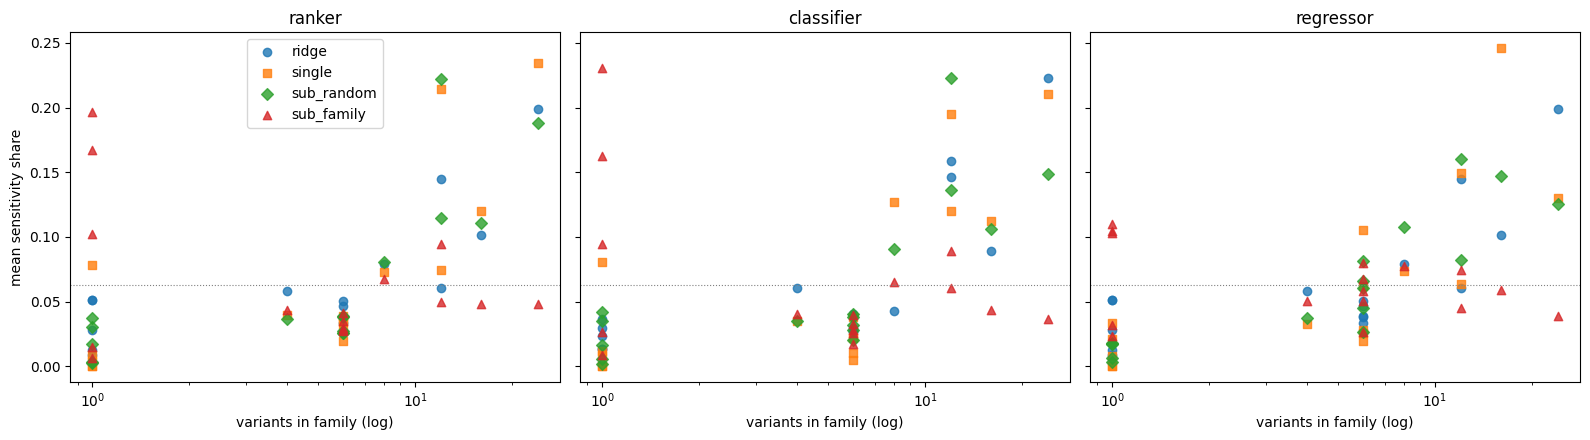

spearman(share, variants)                             
                               ridge single sub_family sub_random
classifier                      0.81   0.76      -0.02       0.76
ranker                          0.73   0.76       0.07       0.81
regressor                       0.73   0.82      -0.16       0.94

head,variants,random/family classifier,random/family ranker,random/family regressor
family,,,,
nhlr,24,4.07,3.89,3.22
macd,16,2.46,2.29,2.52
rlzvol,12,2.24,2.31,1.82
beta_market,12,2.50,2.34,2.16
slope,8,1.39,1.20,1.39
rets,6,1.25,1.10,1.04
retv,6,1.11,0.88,1.01
sma_dist,6,1.14,0.92,0.97
skew,6,0.97,0.93,1.00


In [6]:
sens['share'] = sens.sens / sens.groupby(['year', 'head', 'arm']).sens.transform('sum')
share = sens.groupby(['head', 'arm', 'family']).share.mean().unstack('family')[FAMILIES]
variants = exposure['variants']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, head in zip(axes, HEADS):
    for arm, marker in zip(ARMS, 'osD^'):
        ax.scatter(variants, share.loc[(head, arm)], label=arm, marker=marker, alpha=.8)
    ax.axhline(1 / len(FAMILIES), color='grey', lw=.8, ls=':')
    ax.set_xscale('log')
    ax.set_title(head)
    ax.set_xlabel('variants in family (log)')
axes[0].set_ylabel('mean sensitivity share')
axes[0].legend()
plt.tight_layout()
plt.show()

rho = pd.DataFrame({
    (head, arm): stats.spearmanr(variants, share.loc[(head, arm)]).statistic
    for head in HEADS for arm in ARMS
}, index=['spearman(share, variants)']).T.unstack()
display(rho.round(2))

ratio = (share.xs('sub_random', level='arm') / share.xs('sub_family', level='arm')).T
ratio.insert(0, 'variants', variants)
display(ratio.round(2).rename(columns=lambda c: f'random/family {c}' if c != 'variants' else c))

Reading: if the bias is real, `sub_random`'s share rises with variant count and
the `random/family` ratio is above 1 for many-variant families and below 1 for
single-column families. `single` and `ridge` are references: a single GBDT picks
features greedily, so duplication should matter less; ridge spreads weight over
collinear copies, so duplication also inflates it.

Per-year stability of the random/family ratio for the two extremes:

In [7]:
by_year = sens.pivot_table(index=['head', 'year', 'family'], columns='arm', values='share')
by_year = (by_year.sub_random / by_year.sub_family).unstack('family')
many = variants[variants >= 12].index.tolist()
single_col = variants[variants == 1].index.tolist()
stab = pd.DataFrame({'many-variant families (>=12)': np.exp(np.log(by_year[many]).mean(axis=1)),
                     'single-column families': np.exp(np.log(by_year[single_col]).mean(axis=1))})
display(stab.unstack('head').round(2))

many-variant families (>=12)                  single-column families  \
head                   classifier ranker regressor             classifier   
year                                                                        
2011                         3.07   2.98      2.44                   0.24   
2012                         3.27   3.02      2.19                   0.14   
2013                         3.09   3.15      2.28                   0.21   
2014                         2.83   3.46      2.31                   0.22   
2015                         2.58   2.35      2.29                   0.23   
2016                         3.57   3.27      2.30                   0.19   
2017                         2.83   2.89      1.98                   0.16   
2018                         2.66   2.81      2.26                   0.18   
2019                         2.35   2.55      2.42                   0.20   
2020                         2.58   2.42      2.40                   0.16   
2021                         2.28   2.21      2.27                   0.20   
2022                         2.54   2.45      2.51                   0.24   
2023                         2.75   2.36      2.57                   0.22   
2024                         2.87   2.36      2.75                   0.23   
2025                         2.67   2.45      2.98                   0.21   
2026                         2.48   2.50      3.25                   0.21   

                       
head ranker regressor  
year                   
2011   0.21      0.19  
2012   0.21      0.14  
2013   0.20      0.19  
2014   0.25      0.15  
2015   0.31      0.14  
2016   0.28      0.23  
2017   0.21      0.20  
2018   0.23      0.18  
2019   0.18      0.17  
2020   0.17      0.16  
2021   0.16      0.16  
2022   0.26      0.13  
2023   0.22      0.17  
2024   0.19      0.09  
2025   0.18      0.15  
2026   0.23      0.18

## 6. Secondary read — walk-forward books

Signal at month-end close, enter at the next business day close, exit at the
next rebalance's entry. Equal weight, gross, cash when the book is empty.

In [8]:
close = inputs['close_adj'].unstack('code').reindex(calendar)
sig = signal_dates[signal_dates.year >= years[0]]
entry = calendar[np.minimum(calendar.get_indexer(sig) + 1, len(calendar) - 1)]
periods = pd.DataFrame({'signal': sig[:-1], 'entry': entry[:-1], 'exit': entry[1:]})
periods = periods[periods.exit > periods.entry]
fwd = pd.DataFrame({r.signal: close.loc[r.exit] / close.loc[r.entry] - 1 for r in periods.itertuples()}).T


def book(head, arm):
    p_ = preds[head, arm]
    rows = []
    for d in periods.signal:
        s = p_.loc[d].dropna()
        if head == 'ranker':
            chosen = s.sort_values(ascending=False, kind='mergesort').index[:TOP_N]
        elif head == 'classifier':
            chosen = s.index[s > (0.0 if arm == 'ridge' else 0.5)]  # ridge logit margin vs probability
        else:
            chosen = s.index[s > 0]
        rows.append(pd.Series(1.0 / len(chosen) if len(chosen) else 0.0, index=chosen, dtype=float))
    return pd.DataFrame(rows, index=periods.signal).fillna(0.0)


weights = {(h, a): book(h, a) for h in HEADS for a in ARMS}
ew = panel['close_adj'].notna().unstack('code').reindex(periods.signal).fillna(False)
weights['benchmark', 'equal_weight'] = ew.div(ew.sum(axis=1), axis=0)

held_missing = sum(int(((w > 0) & fwd.reindex(columns=w.columns).isna()).to_numpy().sum()) for w in weights.values())
assert held_missing == 0, f'{held_missing} held positions without a period return'
rets = pd.DataFrame({key: (w * fwd.reindex(columns=w.columns)).sum(axis=1) for key, w in weights.items()})
turnover = pd.Series({key: w.diff().abs().sum(axis=1).iloc[1:].mean() / 2 for key, w in weights.items()})
n_held = pd.Series({key: (w > 0).sum(axis=1).mean() for key, w in weights.items()})
cash = pd.Series({key: (w.sum(axis=1) == 0).mean() for key, w in weights.items()})

n = len(rets)
sr = rets.mean() / rets.std() * np.sqrt(12)
summary = pd.DataFrame({
    'ann_ret': rets.mean() * 12, 'ann_vol': rets.std() * np.sqrt(12), 'sharpe': sr,
    'sharpe_se': np.sqrt((1 + sr ** 2 / 2 / 12) / n * 12), 'names_held': n_held,
    'cash_months': cash, 'one_way_turnover': turnover})
print(f'months={n}  {periods.signal.iloc[0].date()} .. {periods.signal.iloc[-1].date()}')
display(summary.round(3))

months=185  2011-01-31 .. 2026-05-29


/var/folders/0p/wm8kfm151r7c_n2_xpj5pd5m0000gn/T/ipykernel_64883/1441250534.py:25: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ew = panel['close_adj'].notna().unstack('code').reindex(periods.signal).fillna(False)


ann_ret  ann_vol  sharpe  sharpe_se  names_held  \
ranker     ridge           0.132    0.142   0.934      0.259       3.000   
           single          0.120    0.154   0.775      0.258       3.000   
           sub_random      0.121    0.142   0.849      0.258       3.000   
           sub_family      0.126    0.141   0.893      0.259       3.000   
classifier ridge           0.088    0.116   0.759      0.258       1.481   
           single          0.075    0.118   0.630      0.257       1.670   
           sub_random      0.039    0.083   0.472      0.256       0.924   
           sub_family      0.069    0.102   0.681      0.257       0.941   
regressor  ridge           0.123    0.146   0.842      0.258      10.022   
           single          0.137    0.148   0.932      0.259       7.557   
           sub_random      0.130    0.147   0.885      0.259       8.227   
           sub_family      0.134    0.149   0.900      0.259       8.184   
benchmark  equal_weight    0.126    0.146   0.866      0.259      10.211   

                         cash_months  one_way_turnover  
ranker     ridge               0.000             0.386  
           single              0.000             0.379  
           sub_random          0.000             0.290  
           sub_family          0.000             0.290  
classifier ridge               0.216             0.360  
           single              0.292             0.394  
           sub_random          0.584             0.173  
           sub_family          0.551             0.227  
regressor  ridge               0.000             0.018  
           single              0.000             0.240  
           sub_random          0.005             0.160  
           sub_family          0.005             0.171  
benchmark  equal_weight        0.000             0.001

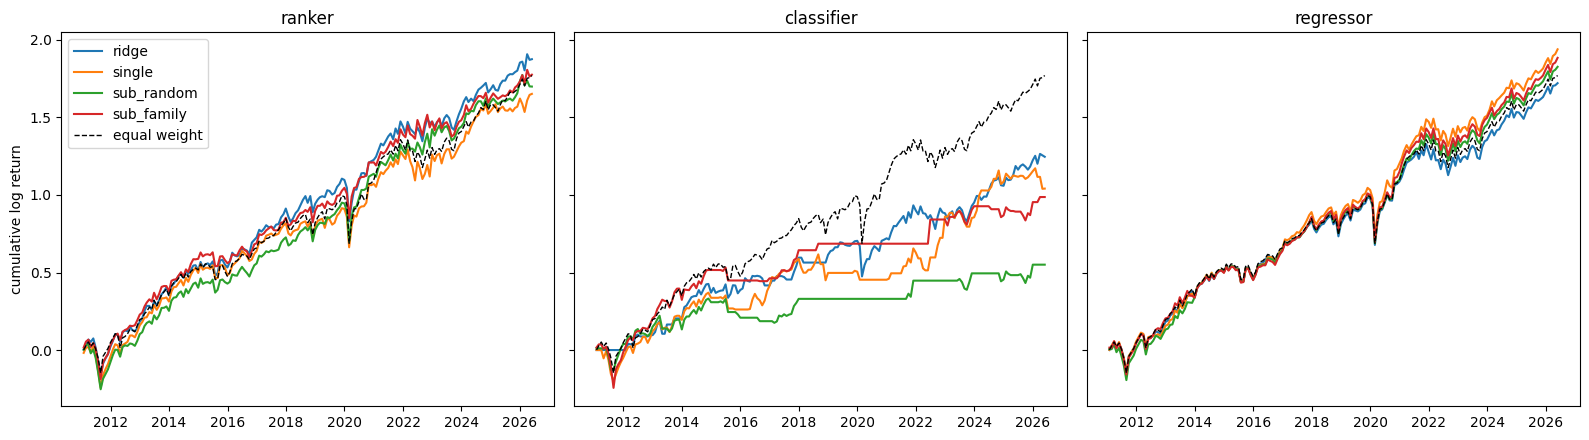

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, head in zip(axes, HEADS):
    for arm in ARMS:
        ax.plot(np.log1p(rets[head, arm]).cumsum(), label=arm)
    ax.plot(np.log1p(rets['benchmark', 'equal_weight']).cumsum(), color='black', lw=1, ls='--', label='equal weight')
    ax.set_title(head)
axes[0].set_ylabel('cumulative log return')
axes[0].legend()
plt.tight_layout()
plt.show()

Paired differences against ridge (same head, same months). Interval: mean
monthly difference ± 1.96 standard errors, annualized. `corr` is the monthly
return correlation with ridge — pairing helps only as far as it is high.

In [10]:
rows = []
for head in HEADS:
    for arm in ARMS[1:] + ['vs_benchmark']:
        a = rets['benchmark', 'equal_weight'] if arm == 'vs_benchmark' else rets[head, arm]
        b = rets[head, 'ridge']
        d = (a - b) if arm != 'vs_benchmark' else (b - a)
        half = 1.96 * d.std() / np.sqrt(n) * 12
        rows.append({'head': head, 'comparison': f'{arm} - ridge' if arm != 'vs_benchmark' else 'ridge - equal weight',
                     'ann_diff': d.mean() * 12, 'ci_low': d.mean() * 12 - half, 'ci_high': d.mean() * 12 + half,
                     'corr': a.corr(b)})
display(pd.DataFrame(rows).set_index(['head', 'comparison']).round(4))

ann_diff  ci_low  ci_high    corr
head       comparison                                             
ranker     single - ridge         -0.0129 -0.0536   0.0277  0.8518
           sub_random - ridge     -0.0116 -0.0445   0.0213  0.8927
           sub_family - ridge     -0.0069 -0.0389   0.0252  0.8965
           ridge - equal weight    0.0062 -0.0228   0.0353  0.9184
classifier single - ridge         -0.0132 -0.0748   0.0484  0.4451
           sub_random - ridge     -0.0487 -0.1026   0.0051  0.4505
           sub_family - ridge     -0.0186 -0.0839   0.0466  0.2823
           ridge - equal weight   -0.0383 -0.0884   0.0118  0.7282
regressor  single - ridge          0.0145 -0.0012   0.0302  0.9771
           sub_random - ridge      0.0070 -0.0095   0.0236  0.9745
           sub_family - ridge      0.0111 -0.0044   0.0266  0.9780
           ridge - equal weight   -0.0032 -0.0087   0.0023  0.9971

## 6b. Diagnostics

Threshold-free view of each model on the month-end rows: the classifier's
predicted probabilities against the 0.5 cut, the within-date Spearman
correlation between prediction and realized target (IC), and a top-3 book
built from every model's scores.

In [11]:
sig_rows = panel.index.get_level_values('date').isin(periods.signal)
target_sig = panel.loc[sig_rows, TARGET]
print(f'classifier label base rate (training rows): {np.nanmean(y_class[np.isfinite(y_all)]):.3f}')

prob = pd.DataFrame({arm: preds['classifier', arm][sig_rows] for arm in ARMS[1:]})
prob['ridge (logistic)'] = 1 / (1 + np.exp(-preds['classifier', 'ridge'][sig_rows]))
dist = prob.describe(percentiles=[.05, .25, .5, .75, .95]).T
dist['share > 0.5'] = (prob > 0.5).mean()
dist['names > 0.5 per month'] = (prob > 0.5).groupby(level='date').sum().mean()
display(dist.drop(columns='count').round(3))

def ic_series(p):
    frame = pd.DataFrame({'p': p[sig_rows], 'y': target_sig}).dropna()
    return frame.groupby(level='date').apply(lambda g: g.p.corr(g.y, method='spearman'))

ic = pd.DataFrame({(h, a): ic_series(preds[h, a]) for h in HEADS for a in ARMS})
display(pd.DataFrame({'mean IC': ic.mean(), 't-stat': ic.mean() / ic.std() * np.sqrt(ic.count()),
                      'months': ic.count()}).round(3))

def top3(p):
    rows = []
    for d in periods.signal:
        s = p.loc[d].dropna().sort_values(ascending=False, kind='mergesort')
        rows.append(pd.Series(1.0 / TOP_N, index=s.index[:TOP_N]))
    return pd.DataFrame(rows, index=periods.signal).fillna(0.0)

top3_rets = pd.DataFrame({(h, a): (top3(preds[h, a]) * fwd).sum(axis=1) for h in HEADS for a in ARMS})
t3 = pd.DataFrame({'ann_ret': top3_rets.mean() * 12, 'ann_vol': top3_rets.std() * np.sqrt(12),
                   'sharpe': top3_rets.mean() / top3_rets.std() * np.sqrt(12)})
for h in HEADS:
    for a in ARMS:
        d = top3_rets[h, a] - top3_rets[h, 'ridge']
        t3.loc[(h, a), 'diff vs ridge'] = d.mean() * 12
        t3.loc[(h, a), 'ci_half'] = 1.96 * d.std() / np.sqrt(len(d)) * 12
display(t3.round(3))

classifier label base rate (training rows): 0.473


,mean,std,min,5%,25%,50%,75%,95%,max,share > 0.5,names > 0.5 per month
single,0.435,0.089,0.169,0.298,0.386,0.429,0.473,0.601,0.817,0.164,1.670
sub_random,0.448,0.044,0.287,0.375,0.423,0.448,0.470,0.524,0.606,0.091,0.924
sub_family,0.442,0.050,0.259,0.356,0.415,0.444,0.470,0.519,0.643,0.092,0.941
ridge (logistic),0.453,0.044,0.310,0.380,0.425,0.452,0.483,0.523,0.563,0.145,1.481


mean IC  t-stat  months
ranker     ridge         0.037   1.279     185
           single       -0.020  -0.719     185
           sub_random    0.017   0.555     185
           sub_family    0.023   0.759     185
classifier ridge         0.054   1.797     185
           single       -0.011  -0.398     185
           sub_random    0.024   0.831     185
           sub_family    0.035   1.144     185
regressor  ridge         0.037   1.279     185
           single        0.036   1.360     185
           sub_random    0.034   1.267     185
           sub_family    0.050   1.776     185

ann_ret  ann_vol  sharpe  diff vs ridge  ci_half
ranker     ridge         0.132    0.142   0.934          0.000    0.000
           single        0.120    0.154   0.775         -0.013    0.041
           sub_random    0.121    0.142   0.849         -0.012    0.033
           sub_family    0.126    0.141   0.893         -0.007    0.032
classifier ridge         0.119    0.133   0.896          0.000    0.000
           single        0.095    0.160   0.591         -0.025    0.041
           sub_random    0.116    0.139   0.831         -0.004    0.030
           sub_family    0.134    0.138   0.975          0.015    0.031
regressor  ridge         0.132    0.142   0.934          0.000    0.000
           single        0.138    0.167   0.824          0.005    0.041
           sub_random    0.127    0.162   0.786         -0.005    0.037
           sub_family    0.143    0.165   0.863          0.010    0.040

## 7. Findings

Numbers below are for tree depth 2 (outputs above are now depth 2 with raw tree inputs;
see the end of this section). Run 2026-10-15 (ridge alpha 10000): p = 111, k = 11, 101 members, 16 yearly fits (2011-2026), 185 monthly periods.

**Primary — the redundancy bias is real and large.** Both subspace arms see the same rows,
parameters and member count; only the subsets differ. Random column subsets give a family
sensitivity share that rises with its variant count (Spearman +0.79 / +0.82 / +0.86 for
classifier / ranker / regressor). Family-balanced subsets remove it (-0.14 / -0.14 / -0.05).
The random/family share ratio runs from about 4x for `nhlr` (24 variants) and 2.5-2.8x for
`macd` (16) down to about 0.2x for every single-column family. The ratio is stable in all 16
fits (families with >= 12 variants: 2.0-3.2x; single-column families: 0.15-0.28x).

Ridge (+0.72 to +0.76) and the single GBDT (+0.74 to +0.81) also correlate with variant
count, so duplication inflates their weights too, or large families also carry more
information; these data cannot separate the two. The random-vs-family comparison is the
clean one. Family-balanced flatness is itself a prior (equal sway per family), not a
measured truth.

**Secondary — P&L does not resolve, and one gap comes from the decision rule.** Sharpe SE
is about 0.26 on every arm; no model beats equal weight.
- Ranker (top 3): all arms within noise of ridge (e.g. single - ridge +0.0%/yr,
  CI [-3.0, +3.0]). Subspace books turn over about half as much as ridge (0.27-0.28 vs
  0.39 one-way per month for ridge). That is deterministic: averaging smooths the scores.
- Classifier (P > 0.5): `sub_random` - ridge -1.4%/yr, CI [-5.3, +2.5]; at ridge alpha 1-1000 this
  was the only resolved gap (-3.9% to -5.3%/yr). At alpha 10000 ridge's own probabilities
  shrink to 0.38-0.52 (5-95%), it holds 1.5 names and sits in cash 21.6% of months. It comes from the rule: averaging pulls probabilities toward the base rate (below
  0.5 for "strictly above median"), so subspace books hold about 2 names instead of
  3.8 and sit in cash 13.5% of months. The models' rankings are not shown to be worse.
- Regressor (prediction > 0): ranked features carry no date-level information, so the
  prediction's sign follows the training mean. Every arm holds 8-10 names, matches equal
  weight (correlation 0.99) and is uninformative.

**Implications.** Use family-balanced subsets, or deduplicate before sampling, whenever
families differ in size. Threshold rules on subspace outputs (P > 0.5, alpha > 0) need
calibration or a cross-sectional rule (top N).

**Ridge needs heavy shrinkage (section 6b).** Mean within-month IC by ridge alpha
1 / 10 / 100 / 1000 / 10000: ranker/regressor 0.015 / 0.013 / 0.018 / 0.040 / 0.037;
classifier -0.002 / -0.002 / 0.010 / 0.043 / 0.054 (t 1.80 at 10000). From alpha 1000 on,
ridge's IC matches the tree models (0.012-0.047); paired sub_family - ridge IC
differences at 10000 are +0.007 / -0.007 / -0.001 (|t| below 0.35). No model's IC is
distinguishable from zero.

**Depth 4 (XGBoost max_depth 4; LightGBM max_depth 4, num_leaves 16).**
The redundancy bias persists: random-subset share vs variant count Spearman +0.89 to
+0.91 (family-balanced -0.13 to -0.18); random/family ratio about 3.6-3.9x for `nhlr`,
about 0.2x for single-column families. Mean IC fell for 8 of 9 strategy/model pairs
(paired depth 4 - depth 2: -0.030 to +0.005; largest |t| 1.90, classifier `single`,
CI [-0.061, +0.001]); none is distinguishable from zero (`tmp/subspace_depth_paired.py`).
Ranker turnover rose (single 0.36 -> 0.47, subspace 0.27-0.28 -> 0.33-0.34).

**Depth 1 (stumps; LightGBM num_leaves 2).** Bias persists (random-subset
Spearman +0.71 to +0.79, family-balanced -0.09 to -0.11). Mean IC, depth 1 / 2 / 4:
ranker single 0.040 / 0.012 / 0.005, sub_random 0.047 / 0.035 / 0.027, sub_family
0.047 / 0.044 / 0.036; classifier single 0.049 / 0.044 / 0.014, sub_random 0.032 / 0.036 /
0.023, sub_family 0.046 / 0.047 / 0.043; regressor single 0.068 / 0.018 / 0.022 (t 2.35 at
depth 1), sub_random 0.024 / 0.040 / 0.031, sub_family 0.037 / 0.036 / 0.031. Of 18 paired
depth comparisons only regressor single depth 1 - depth 2 excludes zero (+0.051,
CI [+0.007, +0.094]); at the 5% level about one of 18 is expected by chance.

**Raw tree inputs, depth 2 (`TREE_INPUT = 'raw'`), outputs above.** Tree models get stored
values with NaN kept; ridge stays ranked; a family is neutralized at its same-date median.
Bias persists for random subsets (Spearman +0.76 to +0.94; family-balanced -0.16 to +0.07).
Mean IC ranked -> raw: ranker single 0.012 -> -0.020, sub_random 0.035 -> 0.017, sub_family
0.044 -> 0.023; classifier single 0.044 -> -0.011, sub_random 0.036 -> 0.024, sub_family
0.047 -> 0.035; regressor single 0.018 -> 0.036, sub_random 0.040 -> 0.034, sub_family
0.036 -> 0.050. No paired raw - ranked difference excludes zero (largest |t| 1.82,
classifier single, CI [-0.115, +0.004]; `tmp/subspace_input_paired.py`). With raw inputs the
absolute rules change: regressor books hold 7.6-8.2 names (ranked: 9.1-10.0) and classifier
books with the probability > 0.5 cut are in cash 29-58% of months.
